# CDC HDP-proxy · перенос 2023 → 2024

**Подготовленный Parquet уже есть; 01 повторно запускать не требуется.** Временную проверку желательно провести до просмотра новых результатов смешанных фолдов 02–05. Пять фолдов **внутри 2023** служат разработкой; затем модели обучаются на всём 2023 и оцениваются на подходящих записях 2024. Это ретроспективная временная проверка, а не внешняя клиническая валидация. Отдельно проверяется, дают ли явные маски пропусков добавку к бустингу, который уже умеет обрабатывать NaN. Предикторы ВРТ и демографии проверяются отдельными чувствительными моделями. Две дополнительные HGB обучаются на составные исходы HDP + роды <37/<34 недель и сверяются с преждевременными родами без записанного HDP; это не диагноз преждевременной ПЭ. Калибровка и переклассификация при фиксированном бюджете 10% оцениваются по ART и социальным группам.

Порог для приблизительно 10% отметок задаётся по OOF-прогнозам 2023 без доступа к распределению прогнозов 2024. Парные интервалы для метрик **основной HDP-proxy** строятся бутстрепом по всем записям 2024; для отдельно обученных составных исходов показываются 2023-фолды и точечные метрики 2024. Без ID матери бутстреп-интервалы могут быть слишком узкими и не учитывают систематическую ошибку метки. Практически заметные различия в метриках **заранее**: ΔAUROC ≥0,01, ΔAUPRC ≥0,01 или абсолютное улучшение Brier ≥0,002; меньшие различия описываются как практически малые даже при узком ДИ. Эти пороги — исследовательская договорённость, не установленный клинический MCID.

2024 год **уже просмотрен экспертом**, включая сравнение составных исходов и вариантов масок. CatBoost и LightGBM добавлены после этого просмотра как исследовательские дополнительные кандидаты; их результаты 2024 не являются независимым подтверждением выбора архитектуры. Поэтому этот тест остаётся ретроспективной проверкой переноса, а не независимой оценкой выбранного победителя. Автоматический выбор типа и параметров во всех трёх поисках использует один критерий — минимум взвешенного OOF `log loss` на соответствующих обучающих фолдах. Сплайн-логистика показывается отдельно как заранее заданный интерпретируемый ориентир; практическая малость разности метрик обсуждается после расчёта, но не подменяет алгоритм выбора. Все варианты 2024 показываются без настройки. Прогноз — частота записанного HDP-proxy, не индивидуальный риск подтверждённой преэклампсии.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/data/preeclampsia_cdc.py").exists())
sys.path.insert(0, str(ROOT))
from src.progress import tqdm
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
BLUE, ORANGE, GREY = "#255B8B", "#D17A31", "#666D78"
MODEL_PALETTE = [("logistic_spline", BLUE), ("hist_gb", ORANGE),
                 ("catboost", "#287D69"), ("lightgbm", "#8062A5")]
RACE6 = {1:"White",2:"Black",3:"AIAN",4:"Asian",5:"NHOPI",6:"Multiple"}  # NCHS MRACE6; social reporting categories
from src.data.preeclampsia_cdc import OUT
from src.training.preeclampsia_cdc import fit_temporal, fit_secondary_temporal, MODEL_NAMES, TEMPORAL_SENSITIVITIES, SECONDARY_TARGETS, metrics
from src.evaluation.preeclampsia_cdc import temporal_summary, temporal_bootstrap, secondary_outcome_metrics, secondary_trained_summary, temporal_subgroup_audit, art_reclassification, compare_guideline_at_budget, decision_curve
from sklearn.calibration import calibration_curve

## Подбор конфигураций только по 2023

До графиков 2024 все конфигурации сравниваются на пяти фолдах 2023. Выбор каждого варианта и общего типа модели основан на взвешенном OOF `log loss` 2023. Результаты выбора на этих же фолдах оптимистичны и служат диагностикой. Сетка была задана заранее; 2024 год уже просматривался в проекте, поэтому последующая временная проверка остаётся исследовательской.

In [2]:
import gc
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve, auc, RocCurveDisplay, PrecisionRecallDisplay
from src.training.preeclampsia_cdc_tuning import (GRID, BASELINE_PARAMS, TUNING_DIR,
    candidate_id, run_grid_search, ablation_results, selected_oof_predictions,
    score_selected_on_2024)
sns.set_theme(style="whitegrid", font_scale=1.0)

## 1. Данные, бюджет поиска и исходные конфигурации

Источник — подготовленный и проверенный `eligible_all_2023_2024.parquet`; в поиск входят только строки 2023. В таблице ниже видно число вариантов на модель. `prevalence` не имеет гиперпараметров и служит контрольной строкой. Сетка задаёт небольшие клинически интерпретируемые изменения регуляризации и сложности; она не гарантирует глобальный математический оптимум.

Подготовленный файл: /Users/nick/Desktop/projects/femfedora/data/processed/preeclampsia_cdc/eligible_all_2023_2024.parquet
2023: 3369714 строк
Всего сочетаний модель × конфигурация × фолд: 110


,model,candidate_id,params,fixed_baseline
0,prevalence,7e05976576b2,{},True
1,logistic,02ea5caad6e8,"{""C"": 0.1}",False
2,logistic,d74a9eb1cd74,"{""C"": 1.0}",True
3,logistic,98aeddc3133d,"{""C"": 10.0}",False
4,logistic_spline,75a0878bb1ff,"{""C"": 0.3, ""n_knots"": 4}",False
5,logistic_spline,248cbd0c8f0f,"{""C"": 0.3, ""n_knots"": 5}",False
6,logistic_spline,1507f32ae96f,"{""C"": 1.0, ""n_knots"": 4}",False
7,logistic_spline,ab5edb235676,"{""C"": 1.0, ""n_knots"": 5}",True
8,logistic_spline,50513708dce2,"{""C"": 3.0, ""n_knots"": 4}",False
9,logistic_spline,247cce42f0e8,"{""C"": 3.0, ""n_knots"": 5}",False


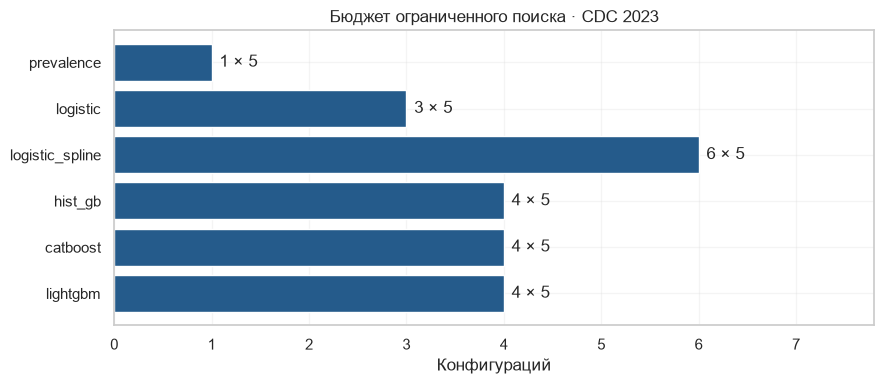

In [3]:
audit=json.loads((OUT/"audit.json").read_text())
print("Подготовленный файл:",OUT/"eligible_all_2023_2024.parquet")
print("2023:",audit["year_checks"]["2023"]["eligible_singleton_rows"],"строк")
print("Всего сочетаний модель × конфигурация × фолд:",5*sum(map(len,GRID.values())))
grid_rows=[{"model":name,"candidate_id":candidate_id(name,params),"params":json.dumps(params,ensure_ascii=False,sort_keys=True),"fixed_baseline":params==BASELINE_PARAMS[name]} for name,items in GRID.items() for params in items]
grid_table=pd.DataFrame(grid_rows)
display(grid_table)
fig,ax=plt.subplots(figsize=(9,4))
counts=grid_table.groupby("model",sort=False).size()
ax.barh(counts.index,counts.values,color=BLUE);ax.invert_yaxis()
ax.set(xlabel="Конфигураций",title="Бюджет ограниченного поиска · CDC 2023")
for i,count in enumerate(counts): ax.text(count+.08,i,f"{count} × 5",va="center")
ax.set_xlim(0,counts.max()*1.3);plt.tight_layout();plt.show()

## 2. Выполнение поиска

Строки 2024 не загружаются как train или validation в этой функции. Запуск может занять много часов на CPU; один поток поиска позволяет контролировать память. Сохранённые результаты проверяются по идентификаторам, меткам и метрикам.

In [4]:
fold_results, summary, best = run_grid_search(resume=True)
print("Общий кандидат:",best["overall_winner"])
display(summary.round(5))
display(pd.DataFrame(best["best_by_model"]).T.round(5))

2023 hyperparameter grid:   0%|          | 0/110 [00:00<?, ?fit/s]

2023 fold 0: hist_gb 422a30:   0%|          | 0/100 [00:00<?, ?tree/s]

2023 fold 0: hist_gb 8b9b7a:   0%|          | 0/100 [00:00<?, ?tree/s]

2023 fold 0: hist_gb 2dc832:   0%|          | 0/100 [00:00<?, ?tree/s]

2023 fold 0: hist_gb 28fde1:   0%|          | 0/100 [00:00<?, ?tree/s]

2023 fold 0: catboost 3970c5:   0%|          | 0/300 [00:00<?, ?tree/s]

... (54 outputs left out)

2023 fold 4: lightgbm c50553:   0%|          | 0/300 [00:00<?, ?tree/s]

Общий кандидат: catboost


,model,candidate_id,params_json,n_oof,events_oof,cv_log_loss,cv_brier,auroc_fold_mean,auroc_fold_sd,auprc_fold_mean,auprc_fold_sd,log_loss_fold_sd,fit_seconds_total,rss_gb_max
0,catboost,08d1effab5f7,"{""depth"": 5, ""l2_leaf_reg"": 8.0}",3369714,348956,0.31597,0.08941,0.66702,0.00057,0.19089,0.00117,0.00047,162.25957,1.70531
1,catboost,97a167526785,"{""depth"": 5, ""l2_leaf_reg"": 3.0}",3369714,348956,0.31597,0.08941,0.66701,0.00060,0.19092,0.00119,0.00047,157.68517,1.83363
2,catboost,baba1e1a2640,"{""depth"": 4, ""l2_leaf_reg"": 8.0}",3369714,348956,0.31600,0.08941,0.66688,0.00063,0.19089,0.00120,0.00046,140.20828,1.95089
3,catboost,3970c5f1f343,"{""depth"": 4, ""l2_leaf_reg"": 3.0}",3369714,348956,0.31601,0.08941,0.66688,0.00059,0.19084,0.00119,0.00047,139.75695,2.14358
4,hist_gb,28fde1366938,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",3369714,348956,0.31602,0.08942,0.66689,0.00052,0.19034,0.00098,0.00047,53.27716,2.03040
5,hist_gb,8b9b7a3ca540,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 15}",3369714,348956,0.31602,0.08942,0.66690,0.00052,0.19030,0.00099,0.00047,54.81671,2.15543
6,hist_gb,2dc832909c75,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 7}",3369714,348956,0.31614,0.08945,0.66643,0.00060,0.18992,0.00096,0.00048,42.81658,2.14735
7,hist_gb,422a3066c0f1,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 7}",3369714,348956,0.31614,0.08945,0.66641,0.00061,0.18993,0.00098,0.00047,43.39617,2.15941
8,lightgbm,c50553e3d039,"{""min_child_samples"": 500, ""num_leaves"": 15}",3369714,348956,0.31599,0.08941,0.66698,0.00052,0.19059,0.00092,0.00047,47.93574,1.85380
9,lightgbm,1f7e1bceccdd,"{""min_child_samples"": 200, ""num_leaves"": 15}",3369714,348956,0.31599,0.08941,0.66698,0.00052,0.19057,0.00091,0.00048,42.76592,1.82272


,candidate_id,params,cv_log_loss,cv_brier,auroc_fold_mean,auprc_fold_mean
prevalence,7e05976576b2,{},0.332828,0.092833,0.5,0.103556
logistic,98aeddc3133d,{'C': 10.0},0.317909,0.089794,0.658271,0.186482
logistic_spline,247cce42f0e8,"{'C': 3.0, 'n_knots': 5}",0.316435,0.089508,0.66501,0.189264
hist_gb,28fde1366938,"{'l2_regularization': 10.0, 'max_leaf_nodes': 15}",0.316022,0.089421,0.666888,0.190343
catboost,08d1effab5f7,"{'depth': 5, 'l2_leaf_reg': 8.0}",0.315972,0.089406,0.667023,0.190891
lightgbm,c50553e3d039,"{'min_child_samples': 500, 'num_leaves': 15}",0.31599,0.089413,0.666982,0.19059


## 3. Абляции: изменение относительно фиксированной конфигурации той же модели

model  candidate_id  \
                                    
0          catboost  08d1effab5f7   
1          catboost  3970c5f1f343   
2          catboost  97a167526785   
3          catboost  baba1e1a2640   
4           hist_gb  28fde1366938   
5           hist_gb  2dc832909c75   
6           hist_gb  422a3066c0f1   
7           hist_gb  8b9b7a3ca540   
8          lightgbm  0fdde8f32384   
9          lightgbm  1f7e1bceccdd   
10         lightgbm  773403994dd7   
11         lightgbm  c50553e3d039   
12         logistic  02ea5caad6e8   
13         logistic  98aeddc3133d   
14         logistic  d74a9eb1cd74   
15  logistic_spline  1507f32ae96f   
16  logistic_spline  247cce42f0e8   
17  logistic_spline  248cbd0c8f0f   
18  logistic_spline  50513708dce2   
19  logistic_spline  75a0878bb1ff   
20  logistic_spline  ab5edb235676   
21       prevalence  7e05976576b2   

                                          params_json is_fixed_baseline  \
                                                                          
0                    {"depth": 5, "l2_leaf_reg": 8.0}              True   
1                    {"depth": 4, "l2_leaf_reg": 3.0}             False   
2                    {"depth": 5, "l2_leaf_reg": 3.0}             False   
3                    {"depth": 4, "l2_leaf_reg": 8.0}             False   
4   {"l2_regularization": 10.0, "max_leaf_nodes": 15}              True   
5    {"l2_regularization": 10.0, "max_leaf_nodes": 7}             False   
6     {"l2_regularization": 1.0, "max_leaf_nodes": 7}             False   
7    {"l2_regularization": 1.0, "max_leaf_nodes": 15}             False   
8         {"min_child_samples": 500, "num_leaves": 7}             False   
9        {"min_child_samples": 200, "num_leaves": 15}              True   
10        {"min_child_samples": 200, "num_leaves": 7}             False   
11       {"min_child_samples": 500, "num_leaves": 15}             False   
12                                         {"C": 0.1}             False   
13                                        {"C": 10.0}             False   
14                                         {"C": 1.0}              True   
15                           {"C": 1.0, "n_knots": 4}             False   
16                           {"C": 3.0, "n_knots": 5}             False   
17                           {"C": 0.3, "n_knots": 5}             False   
18                           {"C": 3.0, "n_knots": 4}             False   
19                           {"C": 0.3, "n_knots": 4}             False   
20                           {"C": 1.0, "n_knots": 5}              True   
21                                                 {}              True   

   delta_log_loss           delta_brier           delta_auroc            \
             mean       std        mean       std        mean       std   
0        0.000000  0.000000    0.000000  0.000000    0.000000  0.000000   
1        0.000035  0.000012    0.000006  0.000003   -0.000145  0.000054   
2        0.000002  0.000014   -0.000000  0.000003   -0.000017  0.000063   
3        0.000030  0.000014    0.000004  0.000003   -0.000145  0.000085   
4        0.000000  0.000000    0.000000  0.000000    0.000000  0.000000   
5        0.000120  0.000018    0.000025  0.000004   -0.000461  0.000089   
6        0.000121  0.000017    0.000026  0.000004   -0.000480  0.000102   
7        0.000002  0.000006    0.000001  0.000002    0.000011  0.000026   
8        0.000018  0.000009    0.000003  0.000002   -0.000077  0.000068   
9        0.000000  0.000000    0.000000  0.000000    0.000000  0.000000   
10       0.000020  0.000009    0.000004  0.000002   -0.000090  0.000052   
11      -0.000002  0.000003   -0.000000  0.000001    0.000005  0.000017   
12       0.000000  0.000000   -0.000000  0.000000   -0.000000  0.000001   
13      -0.000000  0.000000    0.000000  0.000000   -0.000000  0.000000   
14       0.000000  0.000000    0.000000  0.000000    0.000000  0.000000   
15       0.000024  0.000016    0.000004  0.000004

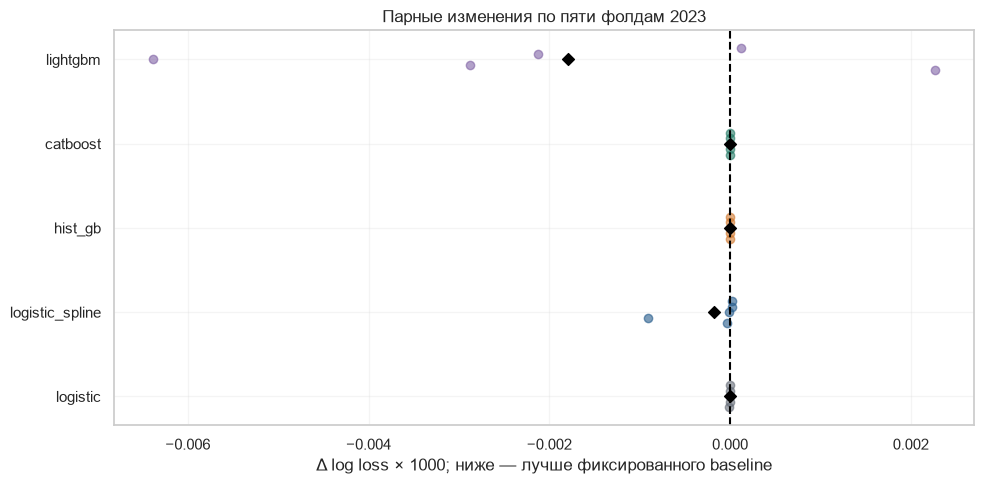

In [5]:
ablation=ablation_results(fold_results)
ablation_summary=ablation.groupby(["model","candidate_id","params_json","is_fixed_baseline"],as_index=False)[["delta_log_loss","delta_brier","delta_auroc","delta_auprc"]].agg(["mean","std"])
display(ablation_summary.round(6))
selected_keys={name:chosen["candidate_id"] for name,chosen in best["best_by_model"].items()}
paired=ablation.loc[ablation.apply(lambda row: row.candidate_id==selected_keys[row.model],axis=1)].copy()
paired["delta_millinat"]=1000*paired.delta_log_loss
fig,ax=plt.subplots(figsize=(10,5))
for i,name in enumerate(MODEL_NAMES[1:]):
    part=paired.loc[paired.model.eq(name)].sort_values("fold")
    ax.scatter(part.delta_millinat,i+np.linspace(-.13,.13,len(part)),color=MODEL_PALETTE[[x for x,_ in MODEL_PALETTE].index(name)][1] if name in dict(MODEL_PALETTE) else GREY,alpha=.6)
    ax.scatter(part.delta_millinat.mean(),i,color="black",marker="D")
ax.axvline(0,color="black",ls="--");ax.set_yticks(range(len(MODEL_NAMES)-1),MODEL_NAMES[1:])
ax.set(xlabel="Δ log loss × 1000; ниже — лучше фиксированного baseline",title="Парные изменения по пяти фолдам 2023")
plt.tight_layout();plt.show()

Точки — именно пять фолдов, ромб — их среднее; это **не** независимые пациенты и не доверительный интервал. Отрицательное изменение `log loss` означает улучшение. При малых различиях важны время, калибровка и перенос, даже если формальный минимум выбран однозначно.

## 4. Карта сетки и цена усложнения

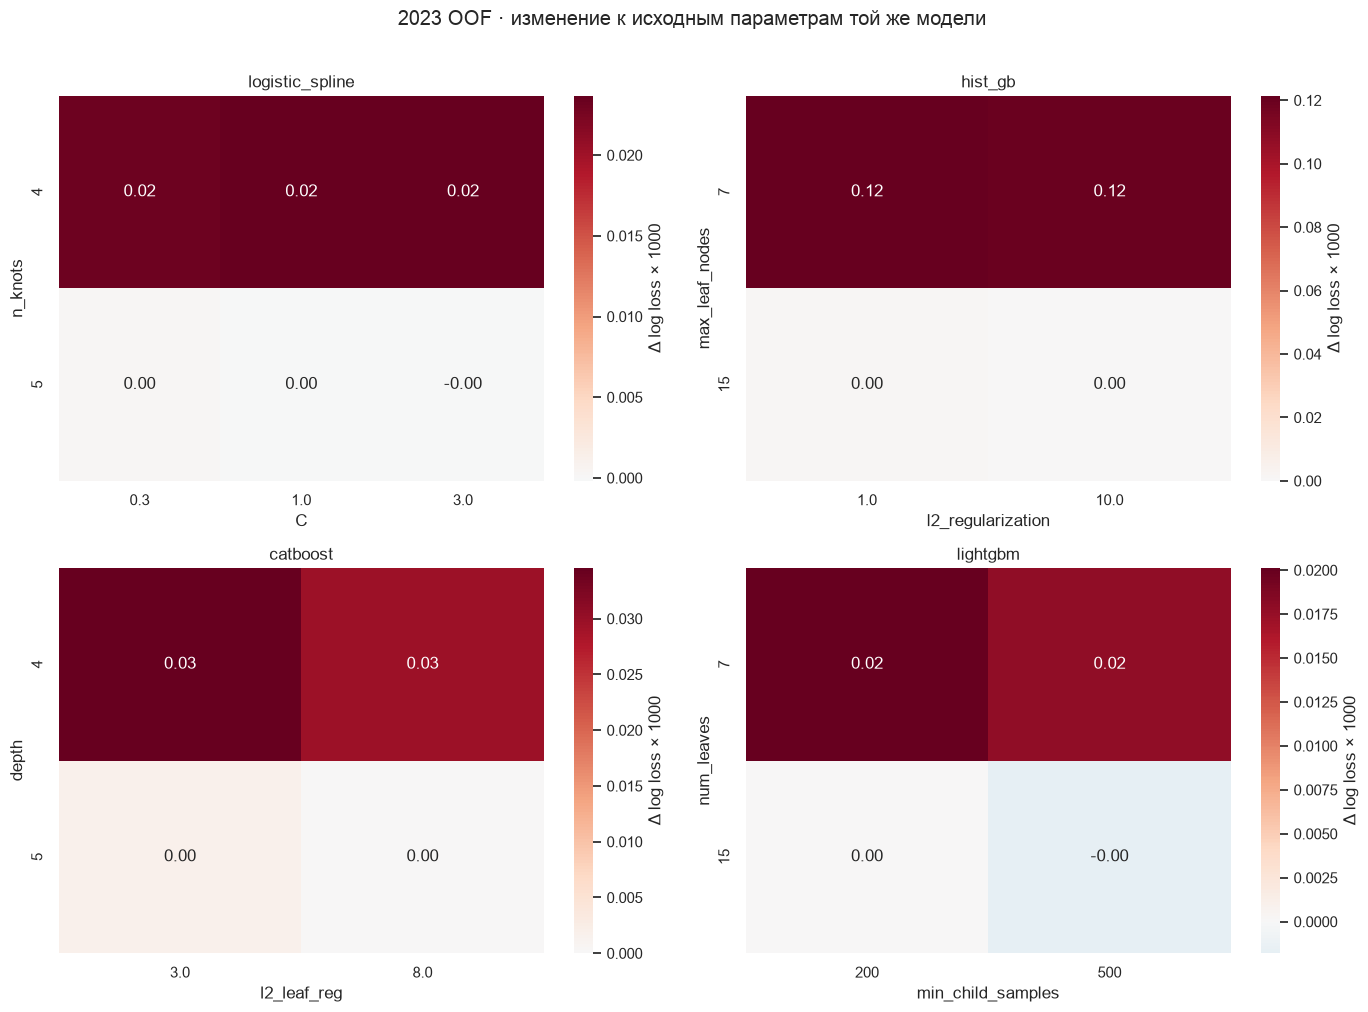

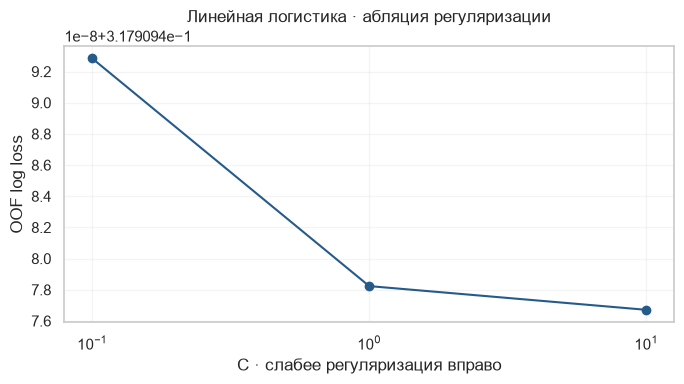

In [6]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
heatmap_specs=[("logistic_spline","n_knots","C"),("hist_gb","max_leaf_nodes","l2_regularization"),("catboost","depth","l2_leaf_reg"),("lightgbm","num_leaves","min_child_samples")]
for ax,(name,row_param,col_param) in zip(axes.flat,heatmap_specs):
    part=summary.loc[summary.model.eq(name)].copy()
    params=part.params_json.map(json.loads)
    part[row_param]=params.map(lambda item:item[row_param])
    part[col_param]=params.map(lambda item:item[col_param])
    baseline=part.loc[part.candidate_id.eq(candidate_id(name,BASELINE_PARAMS[name])),"cv_log_loss"].iloc[0]
    matrix=part.pivot(index=row_param,columns=col_param,values="cv_log_loss")
    sns.heatmap((matrix-baseline)*1000,annot=True,fmt=".2f",cmap="RdBu_r",center=0,ax=ax,cbar_kws={"label":"Δ log loss × 1000"})
    ax.set(title=name,xlabel=col_param,ylabel=row_param)
plt.suptitle("2023 OOF · изменение к исходным параметрам той же модели",y=1.01)
plt.tight_layout();plt.show()
linear=summary.loc[summary.model.eq("logistic")].copy()
linear["C"]=linear.params_json.map(lambda value:json.loads(value)["C"])
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(linear.C,linear.cv_log_loss,marker="o",color=BLUE)
ax.set(xscale="log",xlabel="C · слабее регуляризация вправо",ylabel="OOF log loss",title="Линейная логистика · абляция регуляризации")
plt.tight_layout();plt.show()

## 5. Лучшие варианты: качество и вычислительная цена

,model,candidate_id,params_json,n_oof,events_oof,cv_log_loss,cv_brier,auroc_fold_mean,auroc_fold_sd,auprc_fold_mean,auprc_fold_sd,log_loss_fold_sd,fit_seconds_total,rss_gb_max
0,prevalence,7e05976576b2,{},3369714,348956,0.33283,0.09283,0.50000,0.00000,0.10356,0.00027,0.00058,0.00793,2.00139
1,logistic,98aeddc3133d,"{""C"": 10.0}",3369714,348956,0.31791,0.08979,0.65827,0.00070,0.18648,0.00132,0.00045,6.81384,2.40799
2,logistic_spline,247cce42f0e8,"{""C"": 3.0, ""n_knots"": 5}",3369714,348956,0.31643,0.08951,0.66501,0.00066,0.18926,0.00106,0.00047,11.76074,2.46030
3,hist_gb,28fde1366938,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",3369714,348956,0.31602,0.08942,0.66689,0.00052,0.19034,0.00098,0.00047,53.27716,2.03040
4,catboost,08d1effab5f7,"{""depth"": 5, ""l2_leaf_reg"": 8.0}",3369714,348956,0.31597,0.08941,0.66702,0.00057,0.19089,0.00117,0.00047,162.25957,1.70531
5,lightgbm,c50553e3d039,"{""min_child_samples"": 500, ""num_leaves"": 15}",3369714,348956,0.31599,0.08941,0.66698,0.00052,0.19059,0.00092,0.00047,47.93574,1.85380


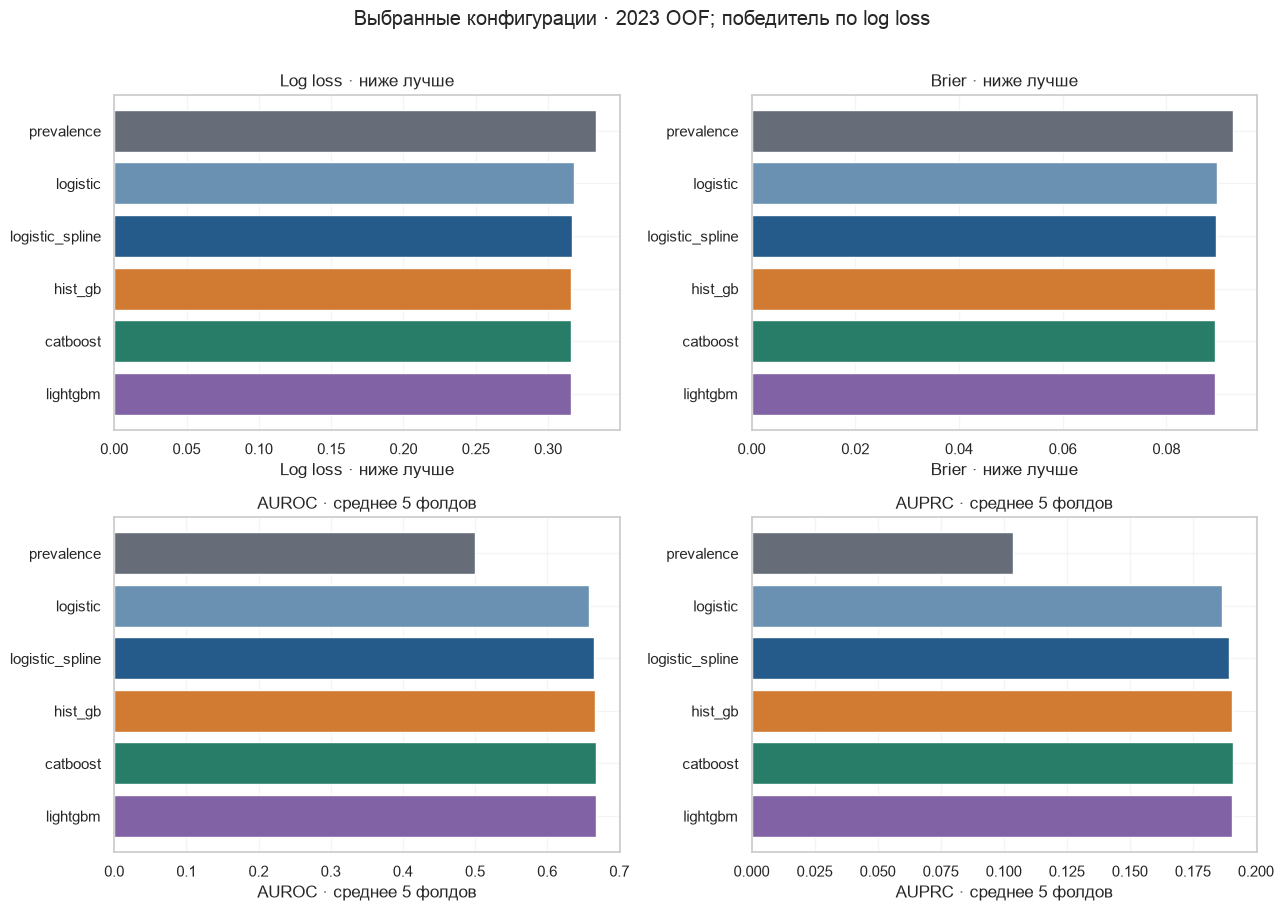

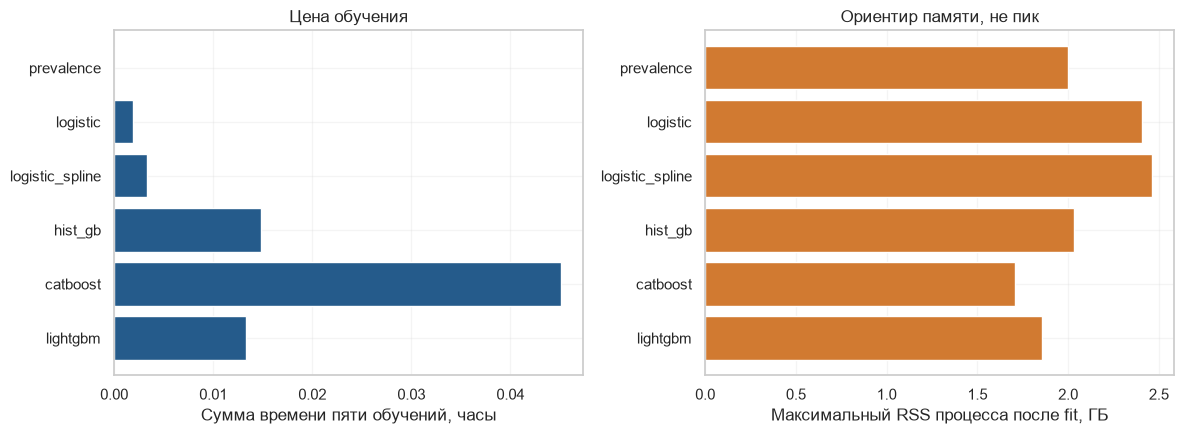

In [7]:
selected_summary=summary.loc[summary.apply(lambda row:row.candidate_id==selected_keys[row.model],axis=1)].set_index("model").reindex(MODEL_NAMES).reset_index()
display(selected_summary.round(5))
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,column,label in zip(axes.flat,["cv_log_loss","cv_brier","auroc_fold_mean","auprc_fold_mean"],["Log loss · ниже лучше","Brier · ниже лучше","AUROC · среднее 5 фолдов","AUPRC · среднее 5 фолдов"]):
    ax.barh(selected_summary.model,selected_summary[column],color=[GREY,"#6A91B1",BLUE,ORANGE,"#287D69","#8062A5"])
    ax.invert_yaxis();ax.set(xlabel=label,title=label)
fig.suptitle("Выбранные конфигурации · 2023 OOF; победитель по log loss",y=1.01)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].barh(selected_summary.model,selected_summary.fit_seconds_total/3600,color=BLUE)
axes[0].set(xlabel="Сумма времени пяти обучений, часы",title="Цена обучения")
axes[1].barh(selected_summary.model,selected_summary.rss_gb_max,color=ORANGE)
axes[1].set(xlabel="Максимальный RSS процесса после fit, ГБ",title="Ориентир памяти, не пик")
for ax in axes:ax.invert_yaxis()
plt.tight_layout();plt.show()

,fold,model,auroc,auprc,brier,log_loss,n,events
17,0,catboost,0.66750,0.19161,0.08932,0.31571,674090,69767
39,1,catboost,0.66774,0.19229,0.08960,0.31642,674392,70049
61,2,catboost,0.66673,0.19116,0.08956,0.31642,674305,69964
83,3,catboost,0.66637,0.18951,0.08940,0.31598,673529,69698
105,4,catboost,0.66678,0.18989,0.08915,0.31533,673398,69478
13,0,hist_gb,0.66722,0.19074,0.08935,0.31580,674090,69767
35,1,hist_gb,0.66760,0.19161,0.08962,0.31649,674392,70049
57,2,hist_gb,0.66669,0.19063,0.08957,0.31645,674305,69964
79,3,hist_gb,0.66628,0.18915,0.08941,0.31601,673529,69698
101,4,hist_gb,0.66666,0.18958,0.08916,0.31536,673398,69478


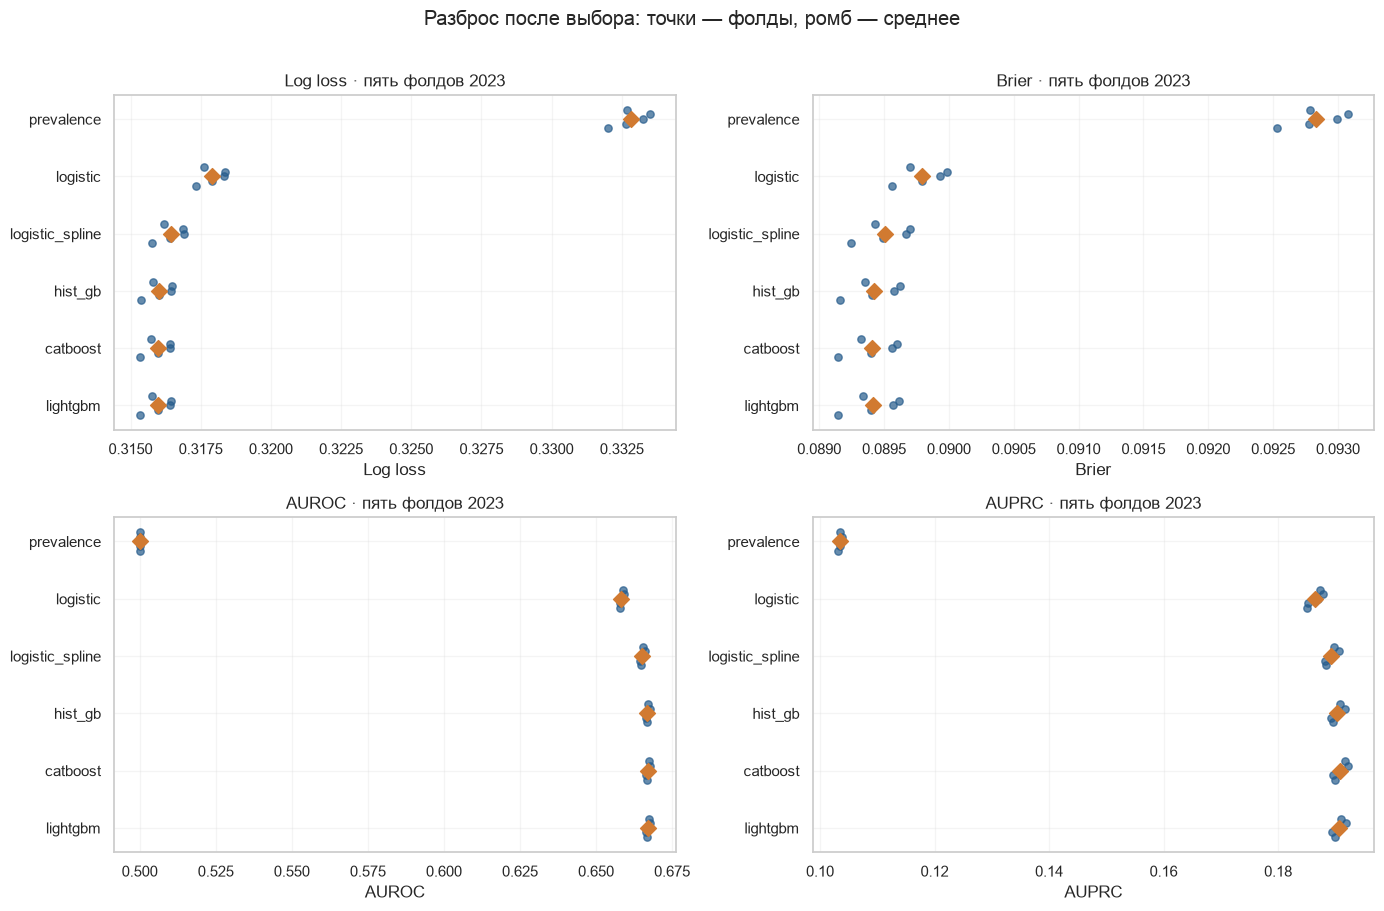

In [8]:
selected_fold=fold_results.loc[fold_results.apply(lambda row:row.candidate_id==selected_keys[row.model],axis=1)].copy()
display(selected_fold[["fold","model","auroc","auprc","brier","log_loss","n","events"]].sort_values(["model","fold"]).round(5))
fig,axes=plt.subplots(2,2,figsize=(14,9))
for ax,metric,title in zip(axes.flat,["log_loss","brier","auroc","auprc"],["Log loss","Brier","AUROC","AUPRC"]):
    for i,name in enumerate(MODEL_NAMES):
        part=selected_fold.loc[selected_fold.model.eq(name)].sort_values("fold")
        ax.scatter(part[metric],i+np.linspace(-.16,.16,5),s=28,alpha=.7,color=BLUE)
        ax.scatter(part[metric].mean(),i,s=65,marker="D",color=ORANGE)
    ax.set_yticks(range(len(MODEL_NAMES)),MODEL_NAMES);ax.invert_yaxis()
    ax.set(xlabel=title,title=f"{title} · пять фолдов 2023")
fig.suptitle("Разброс после выбора: точки — фолды, ромб — среднее",y=1.01)
plt.tight_layout();plt.show()

## 6. Калибровка отложенных прогнозов выбранных конфигураций

На графике все записи 2023 имеют прогноз модели, обученной без их фолда. Выбор конфигураций использовал эти же метки, поэтому эти кривые служат **диагностикой после выбора**, а не независимой оценкой настроенного алгоритма.

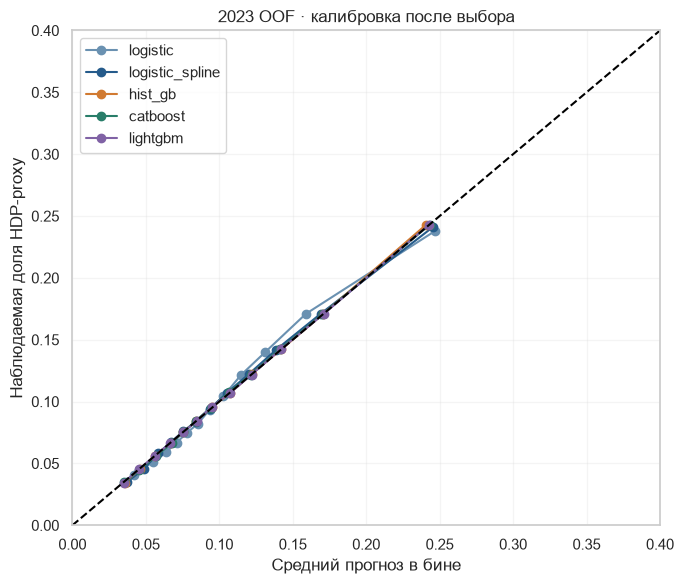

In [9]:
selected_oof=selected_oof_predictions()
fig,ax=plt.subplots(figsize=(7,6))
for name,color in [("logistic","#6A91B1"),*MODEL_PALETTE]:
    observed,predicted=calibration_curve(selected_oof.label,selected_oof[name],n_bins=12,strategy="quantile")
    ax.plot(predicted,observed,marker="o",label=name,color=color)
ax.plot([0,.4],[0,.4],ls="--",color="black")
ax.set(xlim=(0,.4),ylim=(0,.4),xlabel="Средний прогноз в бине",ylabel="Наблюдаемая доля HDP-proxy",title="2023 OOF · калибровка после выбора")
ax.legend();plt.tight_layout();plt.show()

In [10]:
del selected_oof
gc.collect()

64

## Разработка на 2023, финальные модели и полный тест 2024

In [11]:
preliminary=fit_temporal(resume=True)
dev=pd.read_parquet(OUT/"temporal_dev_oof.parquet")
research_candidates=pd.DataFrame([{"model":name,**metrics(dev.label.to_numpy(),dev[name].to_numpy())} for name in MODEL_NAMES])
print("Сплайн-логистика: интерпретируемый ориентир; тип модели выбирается поиском по log loss")
display(research_candidates.round(4))
display(preliminary.round(4))

2023 development CV:   0%|          | 0/5 [00:00<?, ?fold/s]

2023 fold 3: models:   0%|          | 0/8 [00:00<?, ?model/s]

2023 fold 3: hist_gb:   0%|          | 0/100 [00:00<?, ?tree/s]

2023 fold 3: catboost:   0%|          | 0/300 [00:00<?, ?tree/s]

2023 fold 3: lightgbm:   0%|          | 0/300 [00:00<?, ?tree/s]

2023 fold 3: hist_gb_no_masks:   0%|          | 0/100 [00:00<?, ?tree/s]

... (15 outputs left out)

Final 2023: hist_gb_demographic:   0%|          | 0/100 [00:00<?, ?tree/s]

Сплайн-логистика: интерпретируемый ориентир; тип модели выбирается поиском по log loss


,model,auroc,auprc,brier,log_loss,mean_prediction,prevalence
0,prevalence,0.4993,0.1034,0.0928,0.3328,0.1036,0.1036
1,logistic,0.6583,0.1864,0.0898,0.3179,0.1035,0.1036
2,logistic_spline,0.6650,0.1892,0.0895,0.3164,0.1035,0.1036
3,hist_gb,0.6669,0.1904,0.0894,0.3160,0.1036,0.1036
4,catboost,0.6670,0.1908,0.0894,0.3160,0.1036,0.1036
5,lightgbm,0.6670,0.1906,0.0894,0.3160,0.1036,0.1036


,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence
0,prevalence,3394136,363962,0.5000,0.1072,0.0957,0.3408,0.1036,0.1072
1,logistic,3394136,363962,0.6556,0.1910,0.0926,0.3258,0.1040,0.1072
2,logistic_spline,3394136,363962,0.6618,0.1938,0.0923,0.3244,0.1041,0.1072
3,hist_gb,3394136,363962,0.6638,0.1948,0.0922,0.3240,0.1041,0.1072
4,catboost,3394136,363962,0.6639,0.1956,0.0922,0.3239,0.1041,0.1072
5,lightgbm,3394136,363962,0.6639,0.1951,0.0922,0.3240,0.1042,0.1072
6,hist_gb_no_masks,3394136,363962,0.6638,0.1948,0.0922,0.3240,0.1041,0.1072
7,hist_gb_early,3394136,363962,0.6641,0.1952,0.0922,0.3239,0.1042,0.1072
8,hist_gb_demographic,3394136,363962,0.6729,0.2004,0.0919,0.3221,0.1036,0.1072


## Основная оценка и фиксированный по 2023 порог

In [12]:
summary,_=temporal_summary(bootstrap_rounds=0)
display(summary.round(4))

2024 temporal metrics:   0%|          | 0/9 [00:00<?, ?model/s]

,model,n,events,development_threshold_10pct,auroc,auprc,brier,log_loss,mean_prediction,prevalence,...,calibration_slope,joint_calibration_intercept,fixed_flagged_fraction,fixed_true_positive,fixed_false_positive,fixed_true_negative,fixed_false_negative,fixed_sensitivity,fixed_specificity,fixed_ppv
0,prevalence,3394136,363962,NaN,0.5000,0.1072,0.0957,0.3408,0.1036,0.1072,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,logistic,3394136,363962,0.1703,0.6556,0.1910,0.0926,0.3258,0.1040,0.1072,...,0.9907,0.0161,0.1008,80358.0,261761.0,2768413.0,283604.0,0.2208,0.9136,0.2349
2,logistic_spline,3394136,363962,0.1808,0.6618,0.1938,0.0923,0.3244,0.1041,0.1072,...,0.9862,0.0060,0.1013,81782.0,262186.0,2767988.0,282180.0,0.2247,0.9135,0.2378
3,hist_gb,3394136,363962,0.1819,0.6638,0.1948,0.0922,0.3240,0.1041,0.1072,...,1.0002,0.0344,0.1029,83223.0,265891.0,2764283.0,280739.0,0.2287,0.9123,0.2384
4,catboost,3394136,363962,0.1823,0.6639,0.1956,0.0922,0.3239,0.1041,0.1072,...,0.9934,0.0207,0.1010,82097.0,260798.0,2769376.0,281865.0,0.2256,0.9139,0.2394
5,lightgbm,3394136,363962,0.1820,0.6639,0.1951,0.0922,0.3240,0.1042,0.1072,...,0.9887,0.0110,0.1015,82359.0,262237.0,2767937.0,281603.0,0.2263,0.9135,0.2390
6,hist_gb_no_masks,3394136,363962,0.1819,0.6638,0.1948,0.0922,0.3240,0.1041,0.1072,...,1.0002,0.0344,0.1029,83223.0,265891.0,2764283.0,280739.0,0.2287,0.9123,0.2384
7,hist_gb_early,3394136,363962,0.1826,0.6641,0.1952,0.0922,0.3239,0.1042,0.1072,...,0.9988,0.0310,0.1022,82910.0,264079.0,2766095.0,281052.0,0.2278,0.9129,0.2389
8,hist_gb_demographic,3394136,363962,0.1850,0.6729,0.2004,0.0919,0.3221,0.1036,0.1072,...,1.0208,0.0824,0.1001,83480.0,256298.0,2773876.0,280482.0,0.2294,0.9154,0.2457


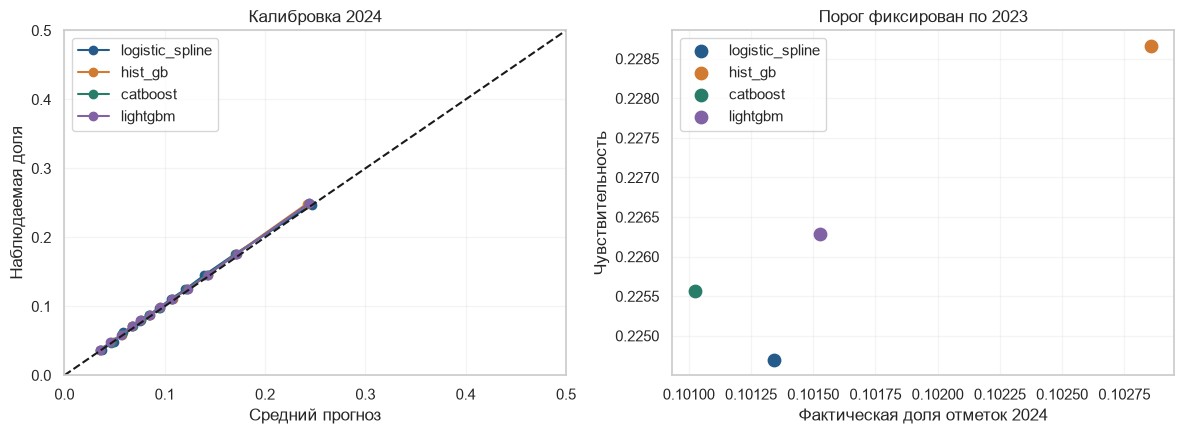

In [13]:
test=pd.read_parquet(OUT/"temporal_test_2024.parquet")
dev=pd.read_parquet(OUT/"temporal_dev_oof.parquet")
assert test.source_year.eq(2024).all() and dev.source_year.eq(2023).all()
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for name,color in MODEL_PALETTE:
    obs,pred=calibration_curve(test.label,test[name],n_bins=12,strategy="quantile")
    axes[0].plot(pred,obs,marker="o",label=name,color=color)
    row=summary.loc[summary.model.eq(name)].iloc[0]
    axes[1].scatter(row.fixed_flagged_fraction,row.fixed_sensitivity,label=name,color=color,s=80)
axes[0].plot([0,.5],[0,.5],"k--");axes[0].set(xlim=(0,.5),ylim=(0,.5),xlabel="Средний прогноз",ylabel="Наблюдаемая доля",title="Калибровка 2024")
axes[1].set(xlabel="Фактическая доля отметок 2024",ylabel="Чувствительность",title="Порог фиксирован по 2023")
for ax in axes:ax.legend()
plt.tight_layout();plt.show()

## Составные вторичные исходы, частичное правило и группы

In [14]:
secondary=secondary_outcome_metrics(test,MODEL_NAMES[1:]+TEMPORAL_SENSITIVITIES)
secondary.to_csv(OUT/"temporal_secondary_outcomes.csv",index=False)
print("Основные модели: только AUROC/AUPRC на составных метках; Brier здесь не применим")
display(secondary.round(4))
rule=pd.concat([compare_guideline_at_budget(test),compare_guideline_at_budget(test,model="hist_gb_early",include_ivf=True)],ignore_index=True)
rule.to_csv(OUT/"temporal_guideline_comparison.csv",index=False)
display(rule.round(4))

Основные модели: только AUROC/AUPRC на составных метках; Brier здесь не применим


,outcome,model,n,events,auroc,auprc
0,target_hdp_preterm37,logistic,3392311,65515,0.6658,0.0443
1,target_hdp_preterm37,logistic_spline,3392311,65515,0.6791,0.0471
2,target_hdp_preterm37,hist_gb,3392311,65515,0.6825,0.0476
3,target_hdp_preterm37,catboost,3392311,65515,0.6830,0.0480
4,target_hdp_preterm37,lightgbm,3392311,65515,0.6830,0.0480
5,target_hdp_preterm37,hist_gb_no_masks,3392311,65515,0.6825,0.0476
6,target_hdp_preterm37,hist_gb_early,3392311,65515,0.6831,0.0476
7,target_hdp_preterm37,hist_gb_demographic,3392311,65515,0.6888,0.0481
8,target_hdp_preterm34,logistic,3392311,16316,0.6671,0.0110
9,target_hdp_preterm34,logistic_spline,3392311,16316,0.6813,0.0119


,model,rule_variant,n,coverage,alert_budget,cases_per_1000,captured_per_1000,flagged_fraction,true_positive,false_positive,true_negative,false_negative,sensitivity,specificity,ppv
0,observed_guideline_subset,core_preconception,3350652,0.9872,0.2028,107.1908,37.1432,0.2028,124454,554911,2436582,234705,0.3465,0.8145,0.1832
1,hist_gb,core_preconception,3350652,0.9872,0.2028,107.1908,41.0249,0.2028,137460,541905,2449588,221699,0.3827,0.8189,0.2023
2,observed_guideline_subset,early_with_ivf,3230478,0.9518,0.2185,107.1875,39.5003,0.2185,127605,578103,2306108,218662,0.3685,0.7996,0.1808
3,hist_gb_early,early_with_ivf,3230478,0.9518,0.2185,107.1875,43.6719,0.2185,141081,564627,2319584,205186,0.4074,0.8042,0.1999


## Отдельное обучение на составных исходах и проверка специфичности

In [15]:
secondary_fits=fit_secondary_temporal(resume=True)
display(secondary_fits.round(4))
composite_comparison,composite_folds=secondary_trained_summary(test)
display(composite_folds.groupby("model")[["auroc","auprc","brier"]].agg(["mean","std"]).round(4))
display(composite_comparison.round(4))

2023 composite development CV:   0%|          | 0/5 [00:00<?, ?fold/s]

2023 fold 0: composites:   0%|          | 0/2 [00:00<?, ?model/s]

2023 fold 0: hist_gb_hdp_preterm37:   0%|          | 0/100 [00:00<?, ?tree/s]

2023 fold 0: hist_gb_hdp_preterm34:   0%|          | 0/100 [00:00<?, ?tree/s]

2023 fold 1: composites:   0%|          | 0/2 [00:00<?, ?model/s]

2023 fold 1: hist_gb_hdp_preterm37:   0%|          | 0/100 [00:00<?, ?tree/s]

... (12 outputs left out)

Final 2023: hist_gb_hdp_preterm34:   0%|          | 0/100 [00:00<?, ?tree/s]

,model,target,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence
0,hist_gb_hdp_preterm37,target_hdp_preterm37,3392311,65515,0.6966,0.0547,0.0186,0.090,0.0190,0.0193
1,hist_gb_hdp_preterm34,target_hdp_preterm34,3392311,16316,0.7063,0.0148,0.0048,0.029,0.0048,0.0048


auroc           auprc           brier        
                         mean     std    mean     std    mean     std
model                                                                
hist_gb_hdp_preterm34  0.7013  0.0029  0.0144  0.0009  0.0047  0.0001
hist_gb_hdp_preterm37  0.6947  0.0014  0.0533  0.0005  0.0182  0.0001

,evaluation_endpoint,score,subset,n,events,auroc,auprc,brier_if_matching_target,calibration_offset_if_matching_target
0,target_hdp_preterm37,hist_gb,all_known_gestation,3392311,65515,0.6825,0.0476,NaN,NaN
1,target_hdp_preterm37,hist_gb_hdp_preterm37,all_known_gestation,3392311,65515,0.6966,0.0547,0.0186,0.0189
2,target_hdp_preterm37,hist_gb_hdp_preterm34,all_known_gestation,3392311,65515,0.6927,0.0531,NaN,NaN
3,target_hdp_preterm34,hist_gb,all_known_gestation,3392311,16316,0.6851,0.0121,NaN,NaN
4,target_hdp_preterm34,hist_gb_hdp_preterm37,all_known_gestation,3392311,16316,0.7041,0.0145,NaN,NaN
5,target_hdp_preterm34,hist_gb_hdp_preterm34,all_known_gestation,3392311,16316,0.7063,0.0148,0.0048,0.0002
6,preterm37_without_recorded_hdp,hist_gb,recorded_hdp_negative_only,3028439,217476,0.5465,0.0884,NaN,NaN
7,preterm37_without_recorded_hdp,hist_gb_hdp_preterm37,recorded_hdp_negative_only,3028439,217476,0.5837,0.1083,NaN,NaN
8,preterm37_without_recorded_hdp,hist_gb_hdp_preterm34,recorded_hdp_negative_only,3028439,217476,0.5884,0.1107,NaN,NaN
9,preterm34_without_recorded_hdp,hist_gb,recorded_hdp_negative_only,3028439,51771,0.5752,0.0243,NaN,NaN


## Абсолютный масштаб при одинаковом числе отметок

На 1000 записей с определимым **частичным** правилом сравниваем число наблюдаемых случаев и найденных случаев при том же бюджете отметок. Для составных исходов используются отдельно обученные HGB 2023 и записи 2024 с известным сроком беременности. Это описательная ретроспективная проверка: правило не включает предыдущую ПЭ, почечные и аутоиммунные болезни и не равно полному USPSTF; аспирин в файле не известен.

,endpoint,model,n,coverage,alert_budget,cases_per_1000,captured_per_1000,sensitivity,ppv
0,target_hdp_proxy,observed_guideline_subset,3350652,0.987,0.203,107.191,37.143,0.347,0.183
1,target_hdp_proxy,hist_gb,3350652,0.987,0.203,107.191,41.025,0.383,0.202
2,target_hdp_preterm37,observed_guideline_subset,3349326,0.987,0.203,19.211,7.539,0.392,0.037
3,target_hdp_preterm37,hist_gb_hdp_preterm37,3349326,0.987,0.203,19.211,8.900,0.463,0.044
4,target_hdp_preterm34,observed_guideline_subset,3349326,0.987,0.203,4.747,1.908,0.402,0.009
5,target_hdp_preterm34,hist_gb_hdp_preterm34,3349326,0.987,0.203,4.747,2.266,0.477,0.011


,endpoint,n_comparable,cases_per_1000,rule_captured_per_1000,model_captured_per_1000,gain_per_1000,alert_budget
0,target_hdp_proxy,3350652,107.191,37.143,41.025,3.882,0.203
1,target_hdp_preterm37,3349326,19.211,7.539,8.900,1.361,0.203
2,target_hdp_preterm34,3349326,4.747,1.908,2.266,0.358,0.203


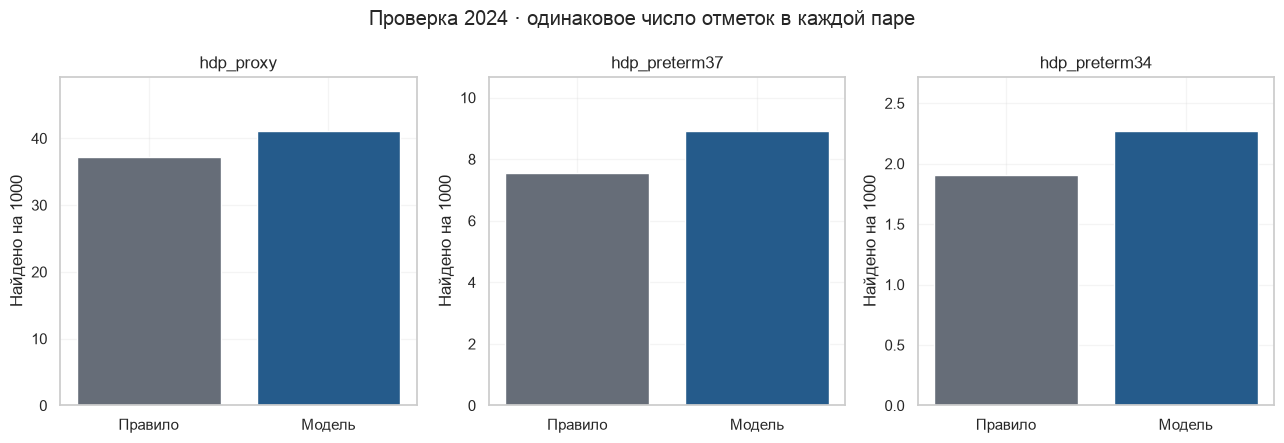

6622

In [16]:
secondary_scores = pd.read_parquet(OUT / "secondary_test_2024.parquet",
    columns=["source_year", "source_row", *SECONDARY_TARGETS])
absolute_frame = test.merge(secondary_scores, on=["source_year", "source_row"],
    how="inner", validate="one_to_one")
assert len(absolute_frame) == len(test)
absolute_rows = []
for endpoint, model in [("target_hdp_proxy", "hist_gb"),
                        ("target_hdp_preterm37", "hist_gb_hdp_preterm37"),
                        ("target_hdp_preterm34", "hist_gb_hdp_preterm34")]:
    label_field = "label" if endpoint == "target_hdp_proxy" else endpoint
    known = absolute_frame.loc[absolute_frame[label_field].notna()].copy()
    known["label"] = known[label_field].astype(np.uint8)
    comparison = compare_guideline_at_budget(known, model=model)
    comparison.insert(0, "endpoint", endpoint)
    absolute_rows.append(comparison)
absolute_table = pd.concat(absolute_rows, ignore_index=True)
absolute_table.to_csv(OUT / "temporal_absolute_per_1000.csv", index=False)
display(absolute_table[["endpoint", "model", "n", "coverage", "alert_budget",
    "cases_per_1000", "captured_per_1000", "sensitivity", "ppv"]].round(3))
absolute_summary = []
for endpoint, model in [("target_hdp_proxy", "hist_gb"),
                        ("target_hdp_preterm37", "hist_gb_hdp_preterm37"),
                        ("target_hdp_preterm34", "hist_gb_hdp_preterm34")]:
    part = absolute_table.loc[absolute_table.endpoint.eq(endpoint)].set_index("model")
    reference = part.loc["observed_guideline_subset"]
    learned = part.loc[model]
    absolute_summary.append({"endpoint": endpoint, "n_comparable": int(reference.n),
        "cases_per_1000": reference.cases_per_1000,
        "rule_captured_per_1000": reference.captured_per_1000,
        "model_captured_per_1000": learned.captured_per_1000,
        "gain_per_1000": learned.captured_per_1000 - reference.captured_per_1000,
        "alert_budget": reference.alert_budget})
absolute_summary = pd.DataFrame(absolute_summary)
absolute_summary.to_csv(OUT / "temporal_absolute_summary_per_1000.csv", index=False)
display(absolute_summary.round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, row in zip(axes, absolute_summary.itertuples()):
    ax.bar(["Правило", "Модель"], [row.rule_captured_per_1000, row.model_captured_per_1000],
           color=[GREY, BLUE])
    ax.set(title=row.endpoint.replace("target_", ""), ylabel="Найдено на 1000",
           ylim=(0, max(1, row.rule_captured_per_1000, row.model_captured_per_1000) * 1.2))
fig.suptitle("Проверка 2024 · одинаковое число отметок в каждой паре")
plt.tight_layout(); plt.show()
del secondary_scores, absolute_frame, absolute_rows
gc.collect()

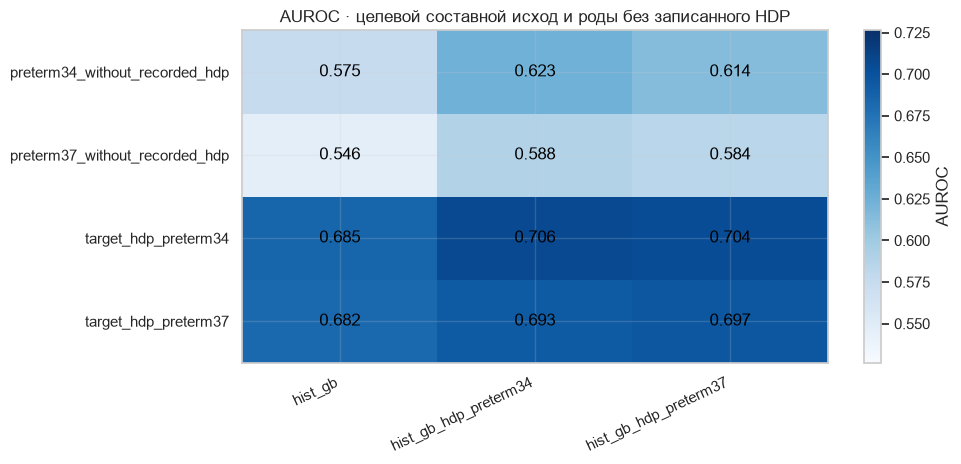

In [17]:
matrix=composite_comparison.pivot(index="evaluation_endpoint",columns="score",values="auroc")
fig,ax=plt.subplots(figsize=(10,4.8))
im=ax.imshow(matrix.to_numpy(),vmin=float(matrix.min().min())-.02,vmax=float(matrix.max().max())+.02,cmap="Blues",aspect="auto")
for i in range(len(matrix)):
    for j in range(len(matrix.columns)): ax.text(j,i,f"{matrix.iloc[i,j]:.3f}",ha="center",va="center",color="black")
ax.set_xticks(range(len(matrix.columns)),matrix.columns,rotation=25,ha="right")
ax.set_yticks(range(len(matrix)),matrix.index)
ax.set(title="AUROC · целевой составной исход и роды без записанного HDP")
fig.colorbar(im,ax=ax,label="AUROC");plt.tight_layout();plt.show()

Строки `preterm*_without_recorded_hdp` рассчитаны **только среди записанных HDP-отрицательных** живорождений. Это проверка общей склонности к преждевременным родам, а не формальный отрицательный контроль и не доказательство специфичности к преэклампсии. Brier/калибровка показаны лишь там, где модель обучена на той же составной метке. Интервал `ILLB_R` остаётся аудитным полем: он измерен до текущих родов, и бинарный порог по нему зависит от длительности текущей беременности у пограничных записей.

In [18]:
sub=temporal_subgroup_audit(dev,test)
art_groups=["art_reported_yes","infertility_treatment_without_art",
            "no_infertility_treatment","art_unknown_reported","art_not_reported"]
display(sub.loc[sub.group.str.startswith(("race_code_","ethnicity_code_")) |
                (sub.group.isin(art_groups) & sub.model.isin(["hist_gb","hist_gb_early"]))].round(4))
reclass=art_reclassification(dev,test)
display(reclass.round(4))

2024 subgroup audit:   0%|          | 0/23 [00:00<?, ?group/s]

,group,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence,...,calibration_in_the_large,development_threshold_10pct,fixed_flagged_fraction,fixed_true_positive,fixed_false_positive,fixed_true_negative,fixed_false_negative,fixed_sensitivity,fixed_specificity,fixed_ppv
15,art_reported_yes,hist_gb,59004,9028,0.6615,0.2586,0.1249,0.4109,0.1210,0.1530,...,0.2837,0.1819,0.1627,2813,6788,43188,6215,0.3116,0.8642,0.2930
19,art_reported_yes,hist_gb_early,59004,9028,0.6624,0.2603,0.1236,0.4061,0.1540,0.1530,...,-0.0076,0.1826,0.3222,4661,14352,35624,4367,0.5163,0.7128,0.2451
22,infertility_treatment_without_art,hist_gb,14944,2392,0.6752,0.2797,0.1281,0.4169,0.1327,0.1601,...,0.2301,0.1819,0.2200,966,2322,10230,1426,0.4038,0.8150,0.2938
26,infertility_treatment_without_art,hist_gb_early,14944,2392,0.6750,0.2777,0.1272,0.4138,0.1579,0.1601,...,0.0172,0.1826,0.3444,1310,3837,8715,1082,0.5477,0.6943,0.2545
29,no_infertility_treatment,hist_gb,3086680,326718,0.6641,0.1928,0.0912,0.3211,0.1035,0.1058,...,0.0255,0.1819,0.1006,73584,236945,2523017,253134,0.2252,0.9141,0.2370
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
156,ethnicity_code_9,catboost,32298,3013,0.6562,0.1697,0.0821,0.2968,0.1002,0.0933,...,-0.0820,0.1823,0.0794,554,2010,27275,2459,0.1839,0.9314,0.2161
157,ethnicity_code_9,lightgbm,32298,3013,0.6562,0.1688,0.0821,0.2968,0.1004,0.0933,...,-0.0839,0.1820,0.0790,555,1996,27289,2458,0.1842,0.9318,0.2176
158,ethnicity_code_9,hist_gb_no_masks,32298,3013,0.6563,0.1697,0.0821,0.2968,0.1003,0.0933,...,-0.0833,0.1819,0.0787,556,1986,27299,2457,0.1845,0.9322,0.2187
159,ethnicity_code_9,hist_gb_early,32298,3013,0.6565,0.1688,0.0821,0.2968,0.1011,0.0933,...,-0.0918,0.1826,0.0809,565,2048,27237,2448,0.1875,0.9301,0.2162


,group,n,events,observed_rate,core_mean_prediction,early_mean_prediction,changed_individual_scores,core_alerts,early_alerts,newly_alerted,newly_alerted_events,no_longer_alerted,no_longer_alerted_events
0,ART_yes_reported,59004,9028,0.1530,0.1210,0.1540,59004,9601,19013,9426,1853,14,5
1,infertility_treatment_without_ART,14944,2392,0.1601,0.1327,0.1579,14944,3288,5147,1861,345,2,1
2,no_infertility_treatment,3086680,326718,0.1058,0.1035,0.1028,3086674,310529,297307,1000,204,14222,2682
3,ART_unknown_reported,1830,278,0.1519,0.1253,0.1486,1830,324,551,228,44,1,0
4,ART_not_reported_core_fallback,231678,25546,0.1103,0.1057,0.1057,0,25372,24971,0,0,401,71


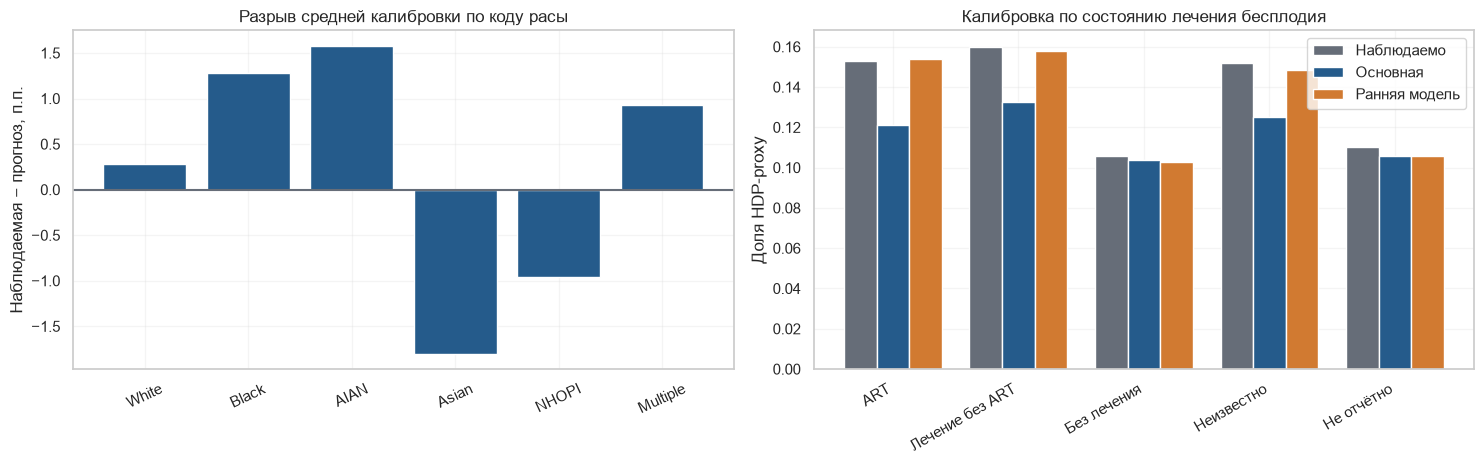

In [19]:
race=sub.loc[sub.model.eq("hist_gb") & sub.group.str.startswith("race_code_")].sort_values("group")
art=sub.loc[sub.group.isin(art_groups) & sub.model.isin(["hist_gb","hist_gb_early"])]
art=art.pivot(index="group",columns="model",values=["prevalence","mean_prediction"]).reindex(art_groups)
fig,axes=plt.subplots(1,2,figsize=(15,4.8))
axes[0].bar([RACE6.get(int(group.rsplit("_",1)[-1]),group) for group in race.group],race.mean_calibration_gap_pp,color=BLUE)
axes[0].axhline(0,color=GREY);axes[0].tick_params(axis="x",rotation=25)
axes[0].set(ylabel="Наблюдаемая − прогноз, п.п.",title="Разрыв средней калибровки по коду расы")
x=np.arange(len(art_groups)); width=.26
axes[1].bar(x-width,art[("prevalence","hist_gb")],width,label="Наблюдаемо",color=GREY)
axes[1].bar(x,art[("mean_prediction","hist_gb")],width,label="Основная",color=BLUE)
axes[1].bar(x+width,art[("mean_prediction","hist_gb_early")],width,label="Ранняя модель",color=ORANGE)
axes[1].set_xticks(x,["ART", "Лечение без ART", "Без лечения", "Неизвестно", "Не отчётно"],rotation=30,ha="right")
axes[1].set(ylabel="Доля HDP-proxy",title="Калибровка по состоянию лечения бесплодия")
axes[1].legend()
plt.tight_layout();plt.show()

`RF_INFTR=1, RF_ARTEC=0` выделено отдельно: отсутствие ART не равнозначно отсутствию лечения бесплодия. Группы на графике взаимоисключающие и покрывают временной тест; число записей и событий показано в таблице выше. Порог здесь означает **верхние 10% прогнозов 2023**, а не клинический порог назначения аспирина. Для неотчётного ART индивидуальные прогнозы ранней и основной моделей равны; их бинарные отметки могут различаться из-за двух разных порогов, рассчитанных на OOF 2023. Коды NCHS: AIAN — American Indian/Alaska Native; NHOPI — Native Hawaiian/Other Pacific Islander. Подгрупповой сдвиг и чувствительность при этом пороге — повод проверить перенос и качество метки, а не автоматически включать расу или обучать отдельную калибровку по каждой группе на том же 2024. Нет сведений о назначении и приёме аспирина; сравнение с частичным правилом USPSTF может быть смещено из-за уже проведённой профилактики. Новый intercept допустимо оценивать только на более поздних независимых размеченных данных и затем проверять на следующем периоде.

## Калибровка по опубликованной расе после исключения импутированных записей

Флаг NCHS восстановлен по исходным строкам и сверяется с подготовленной когортой. Он используется только для аудита, не для обучения. После исключения изменяется состав подгрупп, поэтому разница разрывов не является эффектом самой импутации.

In [20]:
from src.evaluation.preeclampsia_cdc_race import build_race_imputation_rows, race_imputation_sensitivity, RACE_ROWS
if not RACE_ROWS.exists():
    build_race_imputation_rows()
race_temporal = race_imputation_sensitivity(test, ["logistic_spline", "hist_gb"])
race_temporal.to_csv(OUT / "temporal_race_imputation_sensitivity.csv", index=False)
display(race_temporal.round(4))

,year,race_code,subset,model,n,events,event_rate,mean_prediction,mean_calibration_gap_pp
0,2024,1,all,logistic_spline,2530810,268677,0.1062,0.1032,0.2921
1,2024,1,all,hist_gb,2530810,268677,0.1062,0.1033,0.2815
2,2024,1,non_imputed,logistic_spline,2296491,249953,0.1088,0.1034,0.5432
3,2024,1,non_imputed,hist_gb,2296491,249953,0.1088,0.1035,0.5348
4,2024,1,imputed,logistic_spline,234319,18724,0.0799,0.1016,-2.1689
5,2024,1,imputed,hist_gb,234319,18724,0.0799,0.1019,-2.2009
6,2024,2,all,logistic_spline,484706,61181,0.1262,0.1132,1.2997
7,2024,2,all,hist_gb,484706,61181,0.1262,0.1135,1.2760
8,2024,2,non_imputed,logistic_spline,449107,58170,0.1295,0.1139,1.5618
9,2024,2,non_imputed,hist_gb,449107,58170,0.1295,0.1141,1.5388


## Decision curves только для записанной метки

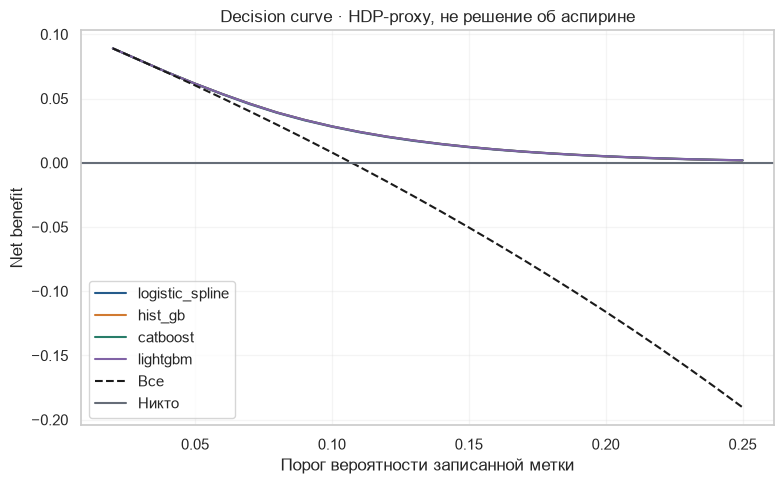

In [21]:
fig,ax=plt.subplots(figsize=(8,5))
for name,color in MODEL_PALETTE:
    curve=decision_curve(test.label.to_numpy(),test[name].to_numpy())
    curve.to_csv(OUT/f"temporal_decision_curve_{name}.csv",index=False)
    ax.plot(curve.threshold,curve.model_net_benefit,label=name,color=color)
ax.plot(curve.threshold,curve.treat_all_net_benefit,"k--",label="Все")
ax.axhline(0,color=GREY,label="Никто")
ax.set(xlabel="Порог вероятности записанной метки",ylabel="Net benefit",title="Decision curve · HDP-proxy, не решение об аспирине")
ax.legend();plt.tight_layout();plt.show()

## Парный бутстреп 2024 · запускать после основных графиков

In [22]:
boot=temporal_bootstrap(bootstrap_rounds=200)
intervals=boot.groupby("model")[["auroc","auprc","brier"]].quantile([.025,.975]).unstack().round(4)
display(intervals)

2024 paired bootstrap:   0%|          | 0/200 [00:00<?, ?replicate/s]

auroc           auprc           brier        
                      0.025   0.975   0.025   0.975   0.025   0.975
model                                                              
catboost             0.6629  0.6649  0.1945  0.1967  0.0920  0.0925
hist_gb              0.6628  0.6647  0.1937  0.1958  0.0920  0.0925
hist_gb_demographic  0.6721  0.6738  0.1994  0.2015  0.0916  0.0921
hist_gb_early        0.6631  0.6650  0.1941  0.1962  0.0920  0.0925
hist_gb_no_masks     0.6628  0.6647  0.1937  0.1958  0.0920  0.0925
lightgbm             0.6629  0.6648  0.1940  0.1961  0.0920  0.0925
logistic             0.6548  0.6565  0.1901  0.1923  0.0924  0.0929
logistic_spline      0.6609  0.6627  0.1926  0.1949  0.0921  0.0926

In [23]:
if not boot.empty:
    comparisons=[]
    for metric, practical_difference in [("auroc",.01),("auprc",.01),("brier",.002)]:
        paired=boot.pivot(index="repeat",columns="model",values=metric)
        for challenger in ["logistic_spline","catboost","lightgbm","hist_gb_no_masks","hist_gb_early","hist_gb_demographic"]:
            delta=paired[challenger]-paired["hist_gb"]
            if metric=="brier": delta=-delta  # положительное значение означает улучшение
            comparisons.append({"metric":metric,"challenger":challenger,"reference":"hist_gb","improvement_mean":delta.mean(),"ci_low":delta.quantile(.025),"ci_high":delta.quantile(.975),"practical_threshold":practical_difference})
    paired_differences=pd.DataFrame(comparisons)
    paired_differences["practically_meaningful"] = paired_differences.improvement_mean.ge(paired_differences.practical_threshold)
    paired_differences["ci_excludes_zero"] = paired_differences.ci_low.gt(0) | paired_differences.ci_high.lt(0)
    paired_differences.to_csv(OUT/"temporal_paired_differences.csv",index=False)
    display(paired_differences.round(4))

,metric,challenger,reference,improvement_mean,ci_low,ci_high,practical_threshold,practically_meaningful,ci_excludes_zero
0,auroc,logistic_spline,hist_gb,-0.0020,-0.0022,-0.0018,0.010,False,True
1,auroc,catboost,hist_gb,0.0001,0.0001,0.0002,0.010,False,True
2,auroc,lightgbm,hist_gb,0.0001,0.0001,0.0002,0.010,False,True
3,auroc,hist_gb_no_masks,hist_gb,0.0000,0.0000,0.0000,0.010,False,False
4,auroc,hist_gb_early,hist_gb,0.0003,0.0002,0.0004,0.010,False,True
5,auroc,hist_gb_demographic,hist_gb,0.0092,0.0089,0.0095,0.010,False,True
6,auprc,logistic_spline,hist_gb,-0.0011,-0.0013,-0.0009,0.010,False,True
7,auprc,catboost,hist_gb,0.0007,0.0006,0.0009,0.010,False,True
8,auprc,lightgbm,hist_gb,0.0003,0.0001,0.0004,0.010,False,True
9,auprc,hist_gb_no_masks,hist_gb,0.0000,0.0000,0.0000,0.010,False,False


## Как читать результат

Разница временного теста и смешанных фолдов показывает перенос между годами. Выбор предпочтительного кандидата и порог основаны только на OOF 2023. 2024 уже просмотрен в экспертном разборе и не даёт независимого подтверждения качества. Поскольку метка объединяет гестационную гипертензию с ПЭ и неполно записывается, калибровка и decision curves относятся **только к свидетельству о рождении**. Нельзя выводить эти проценты пациенткам или использовать график для решения об аспирине без клинической валидации. ПЭ у женщин с хронической АГ и мертворождения вне этой когорты.

## Выбранные по 2023 варианты: исследовательская проверка на 2024

Каждый выбранный вариант обучается на всём 2023 и проверяется на 2024. Параметры не переопределяются по меткам 2024; уже имевшийся просмотр результатов 2024 ограничивает силу вывода.

In [24]:
for old_name in ("dev", "test", "sub"):
    globals().pop(old_name, None)
gc.collect()
selected_oof = selected_oof_predictions()

Selected 2023 fits:   0%|          | 0/5 [00:00<?, ?model/s]

Selected 2023: hist_gb:   0%|          | 0/100 [00:00<?, ?tree/s]

Selected 2023: catboost:   0%|          | 0/300 [00:00<?, ?tree/s]

Selected 2023: lightgbm:   0%|          | 0/300 [00:00<?, ?tree/s]

,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence
0,prevalence,3394136,363962,0.50000,0.10723,0.09575,0.34076,0.10356,0.10723
1,logistic,3394136,363962,0.65560,0.19102,0.09260,0.32578,0.10403,0.10723
2,logistic_spline,3394136,363962,0.66176,0.19377,0.09232,0.32441,0.10414,0.10723
3,hist_gb,3394136,363962,0.66375,0.19484,0.09223,0.32398,0.10414,0.10723
4,catboost,3394136,363962,0.66389,0.19559,0.09221,0.32392,0.10414,0.10723
5,lightgbm,3394136,363962,0.66385,0.19511,0.09222,0.32395,0.10416,0.10723


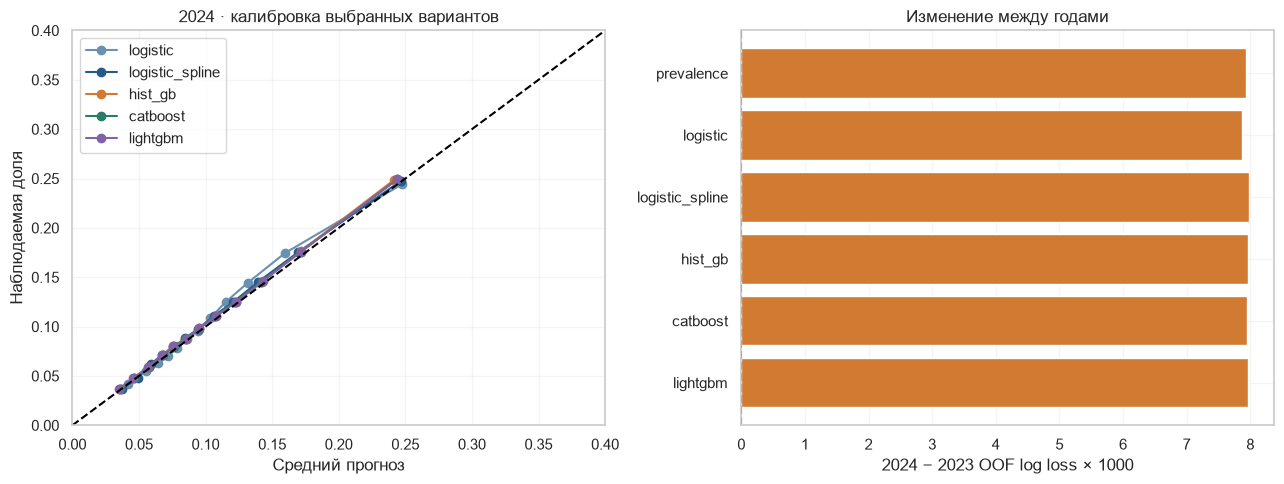

In [25]:
temporal_selected=score_selected_on_2024(resume=True)
display(temporal_selected.round(5))
temporal_scores=pd.read_parquet(TUNING_DIR/"selected_temporal_2024.parquet")
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,color in [("logistic","#6A91B1"),*MODEL_PALETTE]:
    observed,predicted=calibration_curve(temporal_scores.label,temporal_scores[name],n_bins=12,strategy="quantile")
    axes[0].plot(predicted,observed,marker="o",label=name,color=color)
axes[0].plot([0,.4],[0,.4],ls="--",color="black")
axes[0].set(xlim=(0,.4),ylim=(0,.4),xlabel="Средний прогноз",ylabel="Наблюдаемая доля",title="2024 · калибровка выбранных вариантов")
joined=temporal_selected.merge(selected_summary[["model","cv_log_loss"]],on="model")
axes[1].barh(joined.model,1000*(joined.log_loss-joined.cv_log_loss),color=ORANGE)
axes[1].axvline(0,color="black",ls="--");axes[1].invert_yaxis()
axes[1].set(xlabel="2024 − 2023 OOF log loss × 1000",title="Изменение между годами")
axes[0].legend();plt.tight_layout();plt.show()

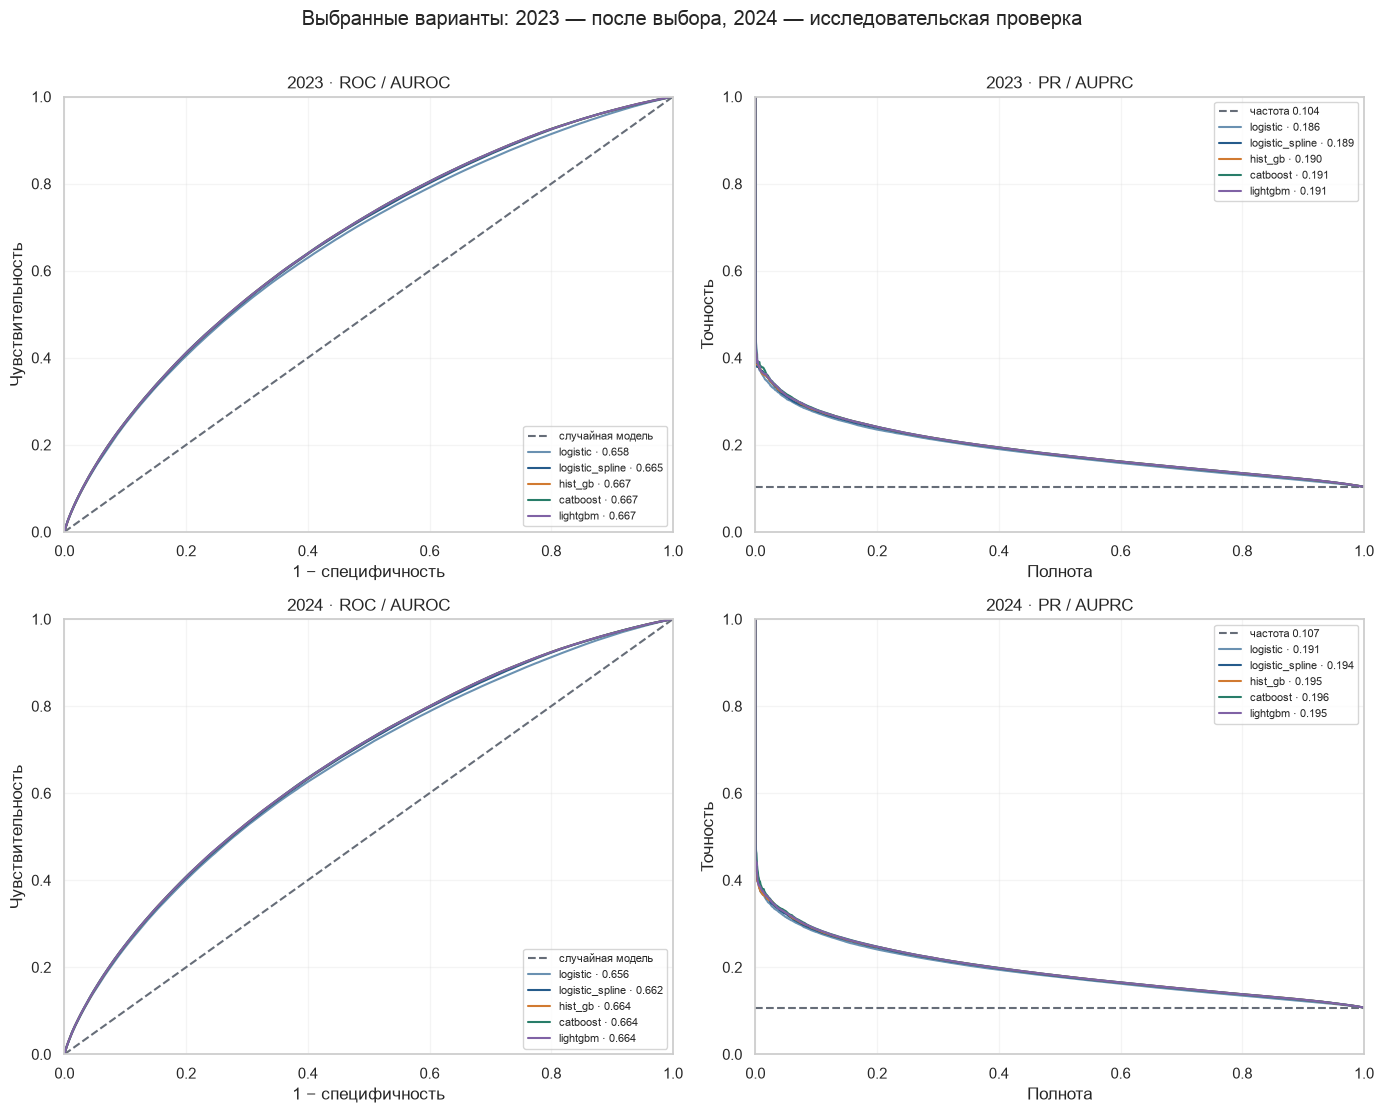

In [26]:
fig,axes=plt.subplots(2,2,figsize=(14,11))
for row,(year,frame) in enumerate([(2023,selected_oof),(2024,temporal_scores)]):
    y=frame.label.to_numpy()
    axes[row,0].plot([0,1],[0,1],ls="--",color=GREY,label="случайная модель")
    axes[row,1].axhline(y.mean(),ls="--",color=GREY,label=f"частота {y.mean():.3f}")
    for name,color in [("logistic","#6A91B1"),*MODEL_PALETTE]:
        p=frame[name].to_numpy()
        fpr,tpr,_=roc_curve(y,p)
        precision,recall,_=precision_recall_curve(y,p)
        roc_points=np.linspace(0,len(fpr)-1,min(len(fpr),1200)).astype(int)
        pr_points=np.linspace(0,len(recall)-1,min(len(recall),1200)).astype(int)
        axes[row,0].plot(fpr[roc_points],tpr[roc_points],label=f"{name} · {auc(fpr,tpr):.3f}",color=color)
        axes[row,1].plot(recall[pr_points],precision[pr_points],label=f"{name} · {-np.sum(np.diff(recall)*precision[:-1]):.3f}",color=color)
    axes[row,0].set(xlim=(0,1),ylim=(0,1),xlabel="1 − специфичность",ylabel="Чувствительность",title=f"{year} · ROC / AUROC")
    axes[row,1].set(xlim=(0,1),ylim=(0,1),xlabel="Полнота",ylabel="Точность",title=f"{year} · PR / AUPRC")
    axes[row,0].legend(fontsize=8,loc="lower right");axes[row,1].legend(fontsize=8,loc="upper right")
fig.suptitle("Выбранные варианты: 2023 — после выбора, 2024 — исследовательская проверка",y=1.01)
plt.tight_layout();plt.show()

Разность `log loss` между 2024 и OOF 2023 объединяет **смену года**, изменение частоты метки и разный объём обучения: OOF-модели обучались на четырёх фолдах, модели для 2024 — на всём 2023. График показывает итоговое изменение качества, но не измеряет отдельно дрейф данных. Выбор настроек по тем же OOF-меткам делает кривые 2023 оптимистичными.